<a href="https://colab.research.google.com/github/ade071212/Tugas-Modul-ML/blob/main/Tugas_Modul_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Latihan 3 – Machine Learning
## Deteksi Gagal Bayar Pinjaman pada Data Tidak Seimbang dan Berisi Missing Values

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

from imblearn.over_sampling import BorderlineSMOTE
from imblearn.under_sampling import RandomUnderSampler

print("Library siap digunakan")

Library siap digunakan


## 1. Menyiapkan Dataset

In [ ]:
gen = np.random.RandomState(11)

arr_x, arr_y = make_classification(
    n_samples=1500, n_features=7, n_informative=4, n_redundant=2,
    weights=[0.92, 0.08], class_sep=0.9, flip_y=0.02, random_state=11)

nama_fitur = ["penghasilan", "rasio_utang", "usia_akun", "jumlah_cicilan",
              "skor_kredit", "saldo_rata2", "tunggakan_lalu"]
X = pd.DataFrame(arr_x, columns=nama_fitur)
y = pd.Series(arr_y, name="gagal_bayar")

# Hapus sebagian nilai (sekitar 10%) pada tiga kolom untuk simulasi data kotor
for kol in ["penghasilan", "skor_kredit", "saldo_rata2"]:
    baris = gen.choice(len(X), size=int(0.10 * len(X)), replace=False)
    X.loc[baris, kol] = np.nan

print("Dimensi X:", X.shape)
X.head()

Dimensi X: (1500, 7)


,penghasilan,rasio_utang,usia_akun,jumlah_cicilan,skor_kredit,saldo_rata2,tunggakan_lalu
0,-0.991212,-1.855613,-0.111672,1.959265,NaN,1.763638,-1.257140
1,-1.271314,-0.020321,-0.005530,2.118665,1.164986,0.889290,0.469705
2,-1.494585,0.223559,-0.318874,1.332320,-1.079862,NaN,0.877934
3,1.369063,1.872952,1.359182,-1.526001,2.252595,2.201894,-2.436249
4,-0.205480,-1.376402,0.470462,-0.301797,-1.869180,1.839710,-3.259622


## 2. Eksplorasi: Distribusi Kelas dan Nilai Kosong

In [ ]:
label = {0: "Lancar (0)", 1: "Gagal bayar (1)"}
print("Jumlah per kelas:\n", y.value_counts().rename(label))
print("\nPersentase:\n", (y.value_counts(normalize=True) * 100).round(1).rename(label))

kosong = X.isna().sum()
kosong = kosong[kosong > 0]
print("\nKolom dengan nilai kosong:\n", kosong)
print("Total sel kosong:", int(X.isna().sum().sum()))

Jumlah per kelas:
 gagal_bayar
Lancar (0)         1357
Gagal bayar (1)     143
Name: count, dtype: int64

Persentase:
 gagal_bayar
Lancar (0)         90.5
Gagal bayar (1)     9.5
Name: proportion, dtype: float64

Kolom dengan nilai kosong:
 penghasilan    150
skor_kredit    150
saldo_rata2    150
dtype: int64
Total sel kosong: 450


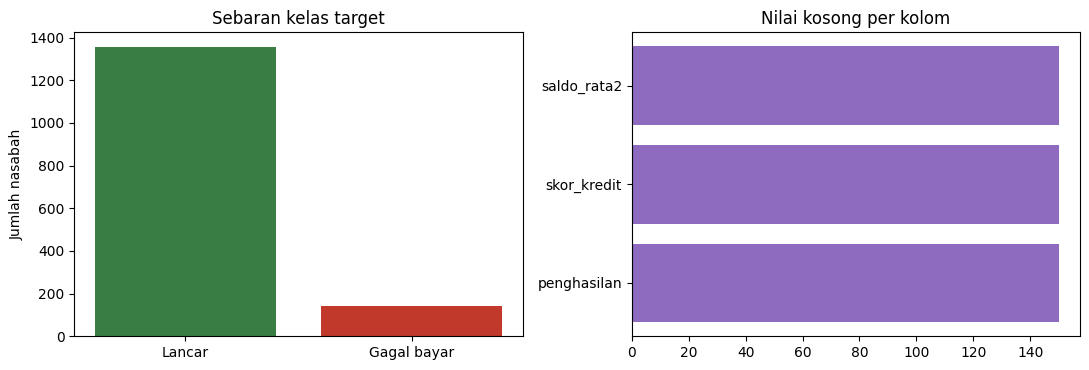

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))

axs[0].bar(["Lancar", "Gagal bayar"], y.value_counts().sort_index().values, color=["#3a7d44", "#c0392b"])
axs[0].set_title("Sebaran kelas target")
axs[0].set_ylabel("Jumlah nasabah")

axs[1].barh(kosong.index, kosong.values, color="#8e6bbf")
axs[1].set_title("Nilai kosong per kolom")

plt.tight_layout()
plt.show()

## 3. Membagi Data (Stratified)

In [ ]:
X_latih, X_uji, y_latih, y_uji = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=11)

print("Latih:", X_latih.shape, "| Uji:", X_uji.shape)
print(f"Gagal bayar di latih: {y_latih.mean():.2%}")
print(f"Gagal bayar di uji  : {y_uji.mean():.2%} ({int(y_uji.sum())} dari {len(y_uji)} nasabah)")

Latih: (1125, 7) | Uji: (375, 7)
Gagal bayar di latih: 9.51%
Gagal bayar di uji  : 9.60% (36 dari 375 nasabah)


## 4. Imputasi Nilai Kosong (fit hanya pada data latih)

In [ ]:
pengisi = IterativeImputer(max_iter=10, random_state=11)
X_latih = pengisi.fit_transform(X_latih)
X_uji = pengisi.transform(X_uji)

print("Sisa NaN latih:", int(np.isnan(X_latih).sum()))
print("Sisa NaN uji  :", int(np.isnan(X_uji).sum()))

Sisa NaN latih: 0
Sisa NaN uji  : 0


## 5. Fungsi Bantu Evaluasi

In [ ]:
tabel_skor = []
matriks = {}

def nilai_model(judul, mdl):
    pred = mdl.predict(X_uji)
    tabel_skor.append({
        "Skenario": judul,
        "Accuracy": accuracy_score(y_uji, pred),
        "Precision": precision_score(y_uji, pred, zero_division=0),
        "Recall": recall_score(y_uji, pred, zero_division=0),
        "F1-score": f1_score(y_uji, pred, zero_division=0)})
    matriks[judul] = confusion_matrix(y_uji, pred)
    print(f"=== {judul} ===")
    print(classification_report(y_uji, pred, target_names=["Lancar", "Gagal bayar"], zero_division=0))

## 6. Pembanding: Selalu Menebak 'Lancar'

In [ ]:
tebak_lancar = DummyClassifier(strategy="most_frequent").fit(X_latih, y_latih)
nilai_model("Selalu Lancar (dummy)", tebak_lancar)

=== Selalu Lancar (dummy) ===
              precision    recall  f1-score   support

      Lancar       0.90      1.00      0.95       339
 Gagal bayar       0.00      0.00      0.00        36

    accuracy                           0.90       375
   macro avg       0.45      0.50      0.47       375
weighted avg       0.82      0.90      0.86       375



## 7. Skenario A: Tanpa Penanganan (Baseline)

In [ ]:
rf_dasar = RandomForestClassifier(n_estimators=200, max_depth=6, random_state=11)
rf_dasar.fit(X_latih, y_latih)
nilai_model("Baseline", rf_dasar)

=== Baseline ===
              precision    recall  f1-score   support

      Lancar       0.94      0.99      0.97       339
 Gagal bayar       0.88      0.42      0.57        36

    accuracy                           0.94       375
   macro avg       0.91      0.71      0.77       375
weighted avg       0.94      0.94      0.93       375



## 8. Skenario B: Borderline-SMOTE (Oversampling)

In [ ]:
X_bs, y_bs = BorderlineSMOTE(random_state=11).fit_resample(X_latih, y_latih)

print("Kelas latih sebelum:", y_latih.value_counts().to_dict())
print("Kelas latih sesudah:", y_bs.value_counts().to_dict())

rf_bs = RandomForestClassifier(n_estimators=200, max_depth=6, random_state=11).fit(X_bs, y_bs)
nilai_model("Borderline-SMOTE", rf_bs)

Kelas latih sebelum: {0: 1018, 1: 107}
Kelas latih sesudah: {0: 1018, 1: 1018}


=== Borderline-SMOTE ===
              precision    recall  f1-score   support

      Lancar       0.97      0.92      0.94       339
 Gagal bayar       0.48      0.69      0.57        36

    accuracy                           0.90       375
   macro avg       0.72      0.81      0.76       375
weighted avg       0.92      0.90      0.91       375



## 9. Skenario C: Random Undersampling

In [ ]:
X_us, y_us = RandomUnderSampler(random_state=11).fit_resample(X_latih, y_latih)

print("Kelas latih sebelum:", y_latih.value_counts().to_dict())
print("Kelas latih sesudah:", y_us.value_counts().to_dict())

rf_us = RandomForestClassifier(n_estimators=200, max_depth=6, random_state=11).fit(X_us, y_us)
nilai_model("Undersampling", rf_us)

Kelas latih sebelum: {0: 1018, 1: 107}
Kelas latih sesudah: {0: 107, 1: 107}


=== Undersampling ===
              precision    recall  f1-score   support

      Lancar       0.97      0.83      0.89       339
 Gagal bayar       0.32      0.75      0.45        36

    accuracy                           0.82       375
   macro avg       0.64      0.79      0.67       375
weighted avg       0.91      0.82      0.85       375



## 10. Skenario D: Class Weight

In [ ]:
rf_bobot = RandomForestClassifier(n_estimators=200, max_depth=6,
                                  class_weight="balanced_subsample", random_state=11)
rf_bobot.fit(X_latih, y_latih)
nilai_model("Class Weight", rf_bobot)

=== Class Weight ===
              precision    recall  f1-score   support

      Lancar       0.96      0.98      0.97       339
 Gagal bayar       0.77      0.64      0.70        36

    accuracy                           0.95       375
   macro avg       0.86      0.81      0.83       375
weighted avg       0.94      0.95      0.94       375



## 11. Perbandingan Hasil

In [ ]:
ringkas = pd.DataFrame(tabel_skor).set_index("Skenario").round(3)
display(ringkas.style.background_gradient(cmap="Purples", subset=["Recall", "F1-score"]).format("{:.3f}"))

,Accuracy,Precision,Recall,F1-score
Skenario,,,,
Selalu Lancar (dummy),0.904,0.000,0.000,0.000
Baseline,0.939,0.882,0.417,0.566
Borderline-SMOTE,0.899,0.481,0.694,0.568
Undersampling,0.821,0.318,0.750,0.446
Class Weight,0.947,0.767,0.639,0.697


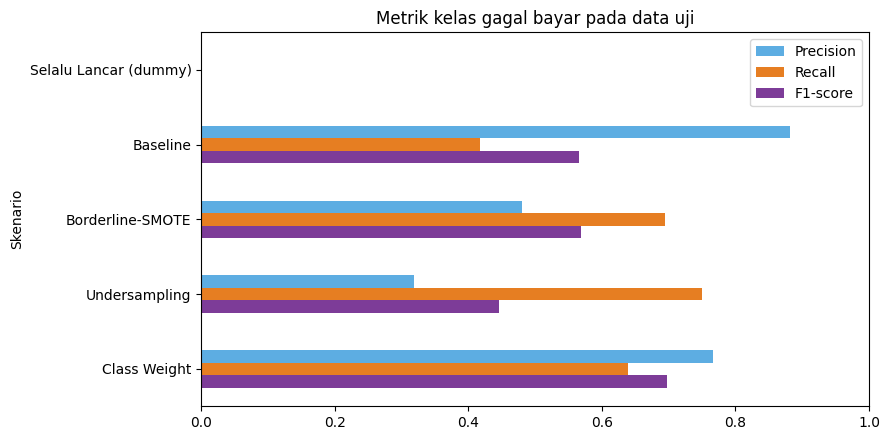

In [ ]:
ringkas[["Precision", "Recall", "F1-score"]].plot(
    kind="barh", figsize=(9, 4.5), color=["#5dade2", "#e67e22", "#7d3c98"])
plt.title("Metrik kelas gagal bayar pada data uji")
plt.xlim(0, 1)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

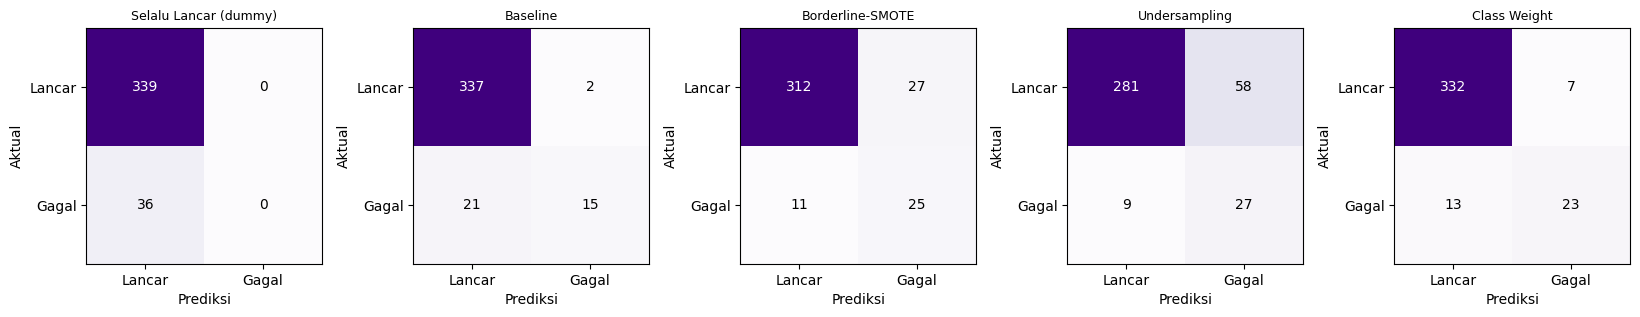

In [ ]:
daftar = list(matriks)
fig, axs = plt.subplots(1, len(daftar), figsize=(3.3 * len(daftar), 3.3))
for ax, judul in zip(axs, daftar):
    cm = matriks[judul]
    ax.imshow(cm, cmap="Purples")
    ax.set_title(judul, fontsize=9)
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(["Lancar", "Gagal"]); ax.set_yticklabels(["Lancar", "Gagal"])
    ax.set_xlabel("Prediksi"); ax.set_ylabel("Aktual")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.tight_layout()
plt.show()

## 12. Keputusan dan Alasan

In [ ]:
calon = ringkas.drop(index="Selalu Lancar (dummy)")
juara_f1 = calon["F1-score"].idxmax()
juara_recall = calon["Recall"].idxmax()

print("-" * 55)
print("Akurasi jika selalu menebak 'Lancar':",
      f"{ringkas.loc['Selalu Lancar (dummy)', 'Accuracy']:.1%}",
      f"(recall = {ringkas.loc['Selalu Lancar (dummy)', 'Recall']:.0%})")
print(f"F1 tertinggi     : {juara_f1} ({calon.loc[juara_f1, 'F1-score']:.3f})")
print(f"Recall tertinggi : {juara_recall} ({calon.loc[juara_recall, 'Recall']:.3f})")
print("-" * 55)

awal = calon.loc["Baseline"]
for skenario in calon.index.drop("Baseline"):
    s = calon.loc[skenario]
    print(f"{skenario:<17} recall {awal['Recall']:.3f}->{s['Recall']:.3f} | "
          f"precision {awal['Precision']:.3f}->{s['Precision']:.3f} | "
          f"F1 {awal['F1-score']:.3f}->{s['F1-score']:.3f}")

-------------------------------------------------------
Akurasi jika selalu menebak 'Lancar': 90.4% (recall = 0%)
F1 tertinggi     : Class Weight (0.697)
Recall tertinggi : Undersampling (0.750)
-------------------------------------------------------
Borderline-SMOTE  recall 0.417->0.694 | precision 0.882->0.481 | F1 0.566->0.568
Undersampling     recall 0.417->0.750 | precision 0.882->0.318 | F1 0.566->0.446
Class Weight      recall 0.417->0.639 | precision 0.882->0.767 | F1 0.566->0.697


### Kesimpulan

In [ ]:
dummy_r = ringkas.loc["Selalu Lancar (dummy)"]
dasar = calon.loc["Baseline"]
bs = calon.loc["Borderline-SMOTE"]
us = calon.loc["Undersampling"]
cw = calon.loc["Class Weight"]
pilihan = juara_f1

print("KESIMPULAN")
print("=" * 60)
print(f"1. Akurasi menyesatkan pada data tidak seimbang. Model yang selalu menebak")
print(f"   'Lancar' mendapat akurasi {dummy_r['Accuracy']:.1%}, tetapi recall gagal bayar")
print(f"   hanya {dummy_r['Recall']:.0%}, sehingga tidak ada nasabah bermasalah yang terdeteksi.")
print()
print(f"2. Baseline memiliki precision {dasar['Precision']:.3f} tetapi recall hanya {dasar['Recall']:.3f},")
print(f"   artinya banyak nasabah gagal bayar yang lolos tidak terdeteksi.")
print()
print("3. Perbandingan teknik penanganan (recall / precision / F1):")
print(f"   - Borderline-SMOTE : {bs['Recall']:.3f} / {bs['Precision']:.3f} / {bs['F1-score']:.3f}")
print(f"   - Undersampling    : {us['Recall']:.3f} / {us['Precision']:.3f} / {us['F1-score']:.3f}")
print(f"   - Class Weight     : {cw['Recall']:.3f} / {cw['Precision']:.3f} / {cw['F1-score']:.3f}")
print()
print(f"4. Teknik terpilih: {pilihan}, karena memberi F1-score tertinggi")
print(f"   ({calon.loc[pilihan, 'F1-score']:.3f}) dengan keseimbangan recall dan precision terbaik.")
print(f"   Recall tertinggi ada pada {juara_recall}, namun dengan biaya precision yang")
print(f"   lebih rendah (banyak alarm palsu).")
print()
print("5. Trade-off: menaikkan recall berarti lebih banyak nasabah gagal bayar terdeteksi,")
print("   tetapi lebih banyak nasabah lancar yang salah ditandai. Pilihan akhir bergantung")
print("   pada mana yang lebih mahal bagi perusahaan: kehilangan uang karena gagal bayar")
print("   yang lolos, atau biaya memeriksa ulang alarm palsu.")
print("   Resampling hanya dilakukan pada data latih agar data uji tetap realistis.")

KESIMPULAN
1. Akurasi menyesatkan pada data tidak seimbang. Model yang selalu menebak
   'Lancar' mendapat akurasi 90.4%, tetapi recall gagal bayar
   hanya 0%, sehingga tidak ada nasabah bermasalah yang terdeteksi.

2. Baseline memiliki precision 0.882 tetapi recall hanya 0.417,
   artinya banyak nasabah gagal bayar yang lolos tidak terdeteksi.

3. Perbandingan teknik penanganan (recall / precision / F1):
   - Borderline-SMOTE : 0.694 / 0.481 / 0.568
   - Undersampling    : 0.750 / 0.318 / 0.446
   - Class Weight     : 0.639 / 0.767 / 0.697

4. Teknik terpilih: Class Weight, karena memberi F1-score tertinggi
   (0.697) dengan keseimbangan recall dan precision terbaik.
   Recall tertinggi ada pada Undersampling, namun dengan biaya precision yang
   lebih rendah (banyak alarm palsu).

5. Trade-off: menaikkan recall berarti lebih banyak nasabah gagal bayar terdeteksi,
   tetapi lebih banyak nasabah lancar yang salah ditandai. Pilihan akhir bergantung
   pada mana yang lebih mahal bagi pe